# 07 - Alternatives & Price Analysis

**Business question:** for a given medicine, how many equivalent brands exist, which is the cheapest, and how much would a patient save?

### Definition of *equivalent alternatives* (kept deliberately strict)
Two brands are alternatives only if they share **the same generic + the same dosage form + the same normalized strength**. We do **not** claim clinical equivalence - only that the label ingredients, form and strength match.

### Price comparability
- Only rows with a non-NULL `price` are used (ambiguous prices stay excluded).
- Prices are compared inside a group, so unit-vs-container differences between forms never mix.
- Groups where the price *basis* differs between brands (`Unit Price` vs described container) are excluded to stay safe.

In [1]:
import sqlite3, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(ROOT / "data" / "medicine.db")      # read-only analysis, nothing is modified
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
C = "#2a6f97"
def bar(s, title, fname, xlabel="", n=15):
    s = s.head(n).iloc[::-1]
    ax = s.plot.barh(color=C, figsize=(8, 0.35*len(s)+1.2)); ax.set_title(title, loc="left", fontweight="bold"); ax.set_ylabel(""); ax.set_xlabel(xlabel)
    for i, v in enumerate(s.values): ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
    plt.tight_layout(); plt.savefig(FIG/fname); plt.show()

In [2]:
m = pd.read_sql("SELECT * FROM vw_medicine_details", con)

m["basis"] = np.where(m.package_description.fillna("").str.startswith("Unit Price"), "unit", "container")
key = ["generic_name","dosage_form_name","strength_normalized"]
base = m.dropna(subset=key)
print(f"Medicines with generic+form+strength defined: {len(base):,} of {len(m):,}")
priced = base.dropna(subset=["price"]).copy()
g = priced.groupby(key)
priced["grp_n"] = g.price.transform("count"); priced["grp_basis"] = g.basis.transform("nunique")
comp = priced[(priced.grp_n >= 2) & (priced.grp_basis == 1)].copy()
print(f"Comparable medicines: {len(comp):,} in {comp.groupby(key).ngroups:,} comparable groups (>=2 priced brands, one price basis)")

Medicines with generic+form+strength defined: 20,863 of 21,714
Comparable medicines: 18,476 in 1,875 comparable groups (>=2 priced brands, one price basis)


## 1. Savings per medicine

For each medicine: `cheapest_in_group` = lowest price among its alternatives; `saving_pct = (price - cheapest) / price`.

Share of medicines that are NOT the cheapest in their group: 79.8%
Median saving by switching to the cheapest alternative: 28.6%  | mean: 30.5%
Medicines where a cheaper equivalent saves >=50%: 15.4%  | >=75%: 1.4%


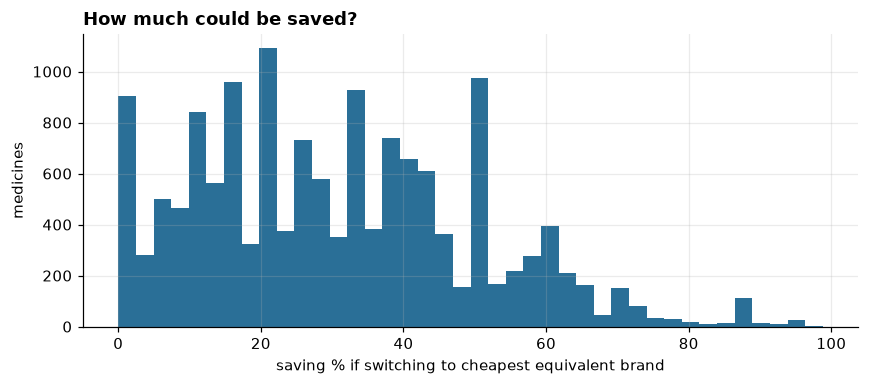

In [3]:
comp["grp_min"] = comp.groupby(key).price.transform("min"); comp["grp_max"] = comp.groupby(key).price.transform("max")
comp["grp_median"] = comp.groupby(key).price.transform("median")
comp["n_alternatives"] = comp.grp_n - 1
comp["saving_amount"] = comp.price - comp.grp_min
comp["saving_pct"] = 100*comp.saving_amount/comp.price
comp["price_index"] = comp.price/comp.grp_median          # 1.0 = group median
s = comp.saving_pct
print(f"Share of medicines that are NOT the cheapest in their group: {(s>0).mean():.1%}")
print(f"Median saving by switching to the cheapest alternative: {s[s>0].median():.1f}%  | mean: {s[s>0].mean():.1f}%")
print(f"Medicines where a cheaper equivalent saves >=50%: {(s>=50).mean():.1%}  | >=75%: {(s>=75).mean():.1%}")
fig, ax = plt.subplots(figsize=(8,3.6)); ax.hist(s[s>0], bins=40, color=C); ax.set_xlabel("saving % if switching to cheapest equivalent brand"); ax.set_ylabel("medicines")
ax.set_title("How much could be saved?", loc="left", fontweight="bold"); plt.tight_layout(); plt.savefig(FIG/"alt_saving_hist.png"); plt.show()

## 2. Group-level comparison (one row per generic + form + strength)

In [4]:
grp = comp.groupby(key).agg(brands=("brand_id","count"), min_price=("price","min"), median_price=("price","median"), max_price=("price","max")).reset_index()
grp["spread_x"] = (grp.max_price/grp.min_price).round(2)
grp["max_saving_pct"] = (100*(grp.max_price-grp.min_price)/grp.max_price).round(1)
print(f"Groups: {len(grp):,} | median brands per group: {grp.brands.median():.0f} | median max/min price ratio: {grp.spread_x.median():.2f}x")
print(f"Groups where the dearest brand costs >= 2x the cheapest: {(grp.spread_x>=2).mean():.1%}")
grp.sort_values(["brands","spread_x"], ascending=False).head(15)

Groups: 1,875 | median brands per group: 5 | median max/min price ratio: 1.33x
Groups where the dearest brand costs >= 2x the cheapest: 23.4%


,generic_name,dosage_form_name,strength_normalized,brands,min_price,median_price,max_price,spread_x,max_saving_pct
1318,Omeprazole,Capsule (Delayed Release),20 mg,117,3.00,5.00,7.10,2.37,57.7
160,Azithromycin Dihydrate,Tablet,500 mg,108,4.00,35.00,55.50,13.88,92.8
625,Domperidone Maleate,Tablet,10 mg,104,1.00,2.00,4.00,4.00,75.0
438,Ciprofloxacin,Tablet,500 mg,104,8.00,14.00,16.05,2.01,50.2
999,Ketorolac Tromethamine,Tablet,10 mg,103,4.00,10.00,45.00,11.25,91.1
3,Aceclofenac,Tablet,100 mg,103,1.50,4.00,5.10,3.40,70.6
1378,Paracetamol + Caffeine,Tablet,500 mg+65 mg,100,1.50,2.00,2.53,1.69,40.7
1518,Ranitidine Hydrochloride,Tablet,150 mg,94,0.77,2.00,4.07,5.29,81.1
338,Cefixime Trihydrate,Capsule,200 mg,93,20.00,35.00,45.00,2.25,55.6
394,Cephradine,Capsule,500 mg,85,10.00,12.54,16.05,1.60,37.7


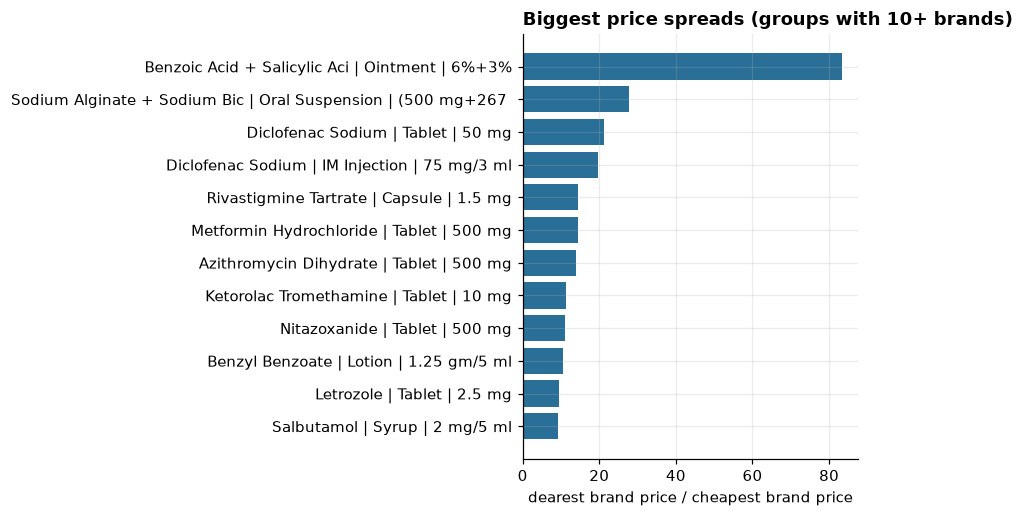

In [5]:
big = grp[grp.brands>=10].sort_values("spread_x", ascending=False).head(12)
lab = big.generic_name.str.slice(0,28)+" | "+big.dosage_form_name+" | "+big.strength_normalized.str.slice(0,12)
fig, ax = plt.subplots(figsize=(8,4.8)); ax.barh(lab[::-1], big.spread_x[::-1], color=C)
ax.set_xlabel("dearest brand price / cheapest brand price"); ax.set_title("Biggest price spreads (groups with 10+ brands)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG/"alt_top_spreads.png"); plt.show()

## 3. Does the number of alternatives relate to price?

In [6]:
grp["bucket"] = pd.cut(grp.brands, [1,2,5,10,1000], labels=["2","3-5","6-10","11+"])
t = grp.groupby("bucket", observed=True).agg(groups=("brands","count"), median_spread=("spread_x","median"), median_saving_pct=("max_saving_pct","median")).round(2); print(t)
print("\nReading: more competing brands -> usually a wider gap between cheapest and dearest.")

        groups  median_spread  median_saving_pct
bucket                                          
2          423           1.06                5.3
3-5        624           1.25               20.0
6-10       375           1.40               28.6
11+        453           1.76               43.0

Reading: more competing brands -> usually a wider gap between cheapest and dearest.


## 4. Manufacturer price positioning

`price_index` = brand price / median price of its group. Index < 1 means cheaper than the typical equivalent brand. Only manufacturers with 30+ comparable medicines are ranked.

107 manufacturers ranked


,n,median_index,pct_cheapest
manufacturer_name,,,
Gonoshasthaya Pharma Ltd.,116,0.76,50.86
Delta Pharma Ltd.,138,0.80,52.90
Marker Pharma Ltd.,32,0.86,3.12
Orbit Pharmaceuticals Ltd.,36,0.86,11.11
Aexim Pharmaceuticals Ltd.,37,0.87,24.32
Bristol Pharmaceuticals Ltd.,77,0.91,18.18
Desh Pharmaceuticals Ltd.,77,0.91,15.58
Doctor’s Chemical Works Ltd.,91,0.92,17.58
Hudson Pharmaceuticals Ltd.,78,0.92,16.67


,n,median_index,pct_cheapest
manufacturer_name,,,
UniMed UniHealth,370,1.00,25.41
Techno Drugs Ltd.,164,1.00,28.66
Team Pharmaceuticals Ltd.,92,1.00,11.96
The White Horse Pharma,109,1.00,13.76
Synovia pharma plc,167,1.01,5.39
GlaxoSmithKline,75,1.08,14.67
SANDOZ (A Novartis Division),85,1.17,3.53
Innovative Pharma (Albion),85,1.18,8.24
Radiant Pharmaceuticals Ltd.,128,1.24,6.25


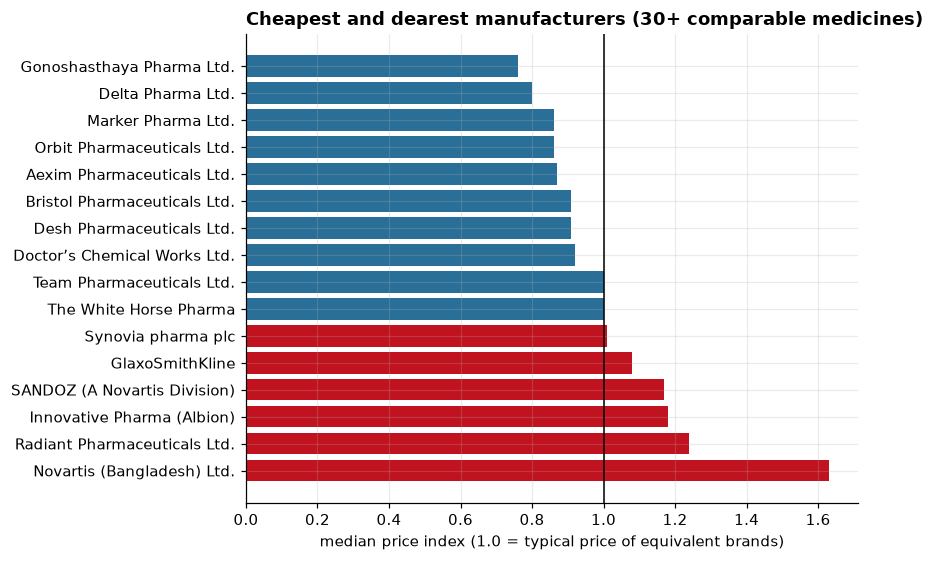

In [7]:
mp = comp.groupby("manufacturer_name").agg(n=("brand_id","count"), median_index=("price_index","median"), pct_cheapest=("saving_pct", lambda x: (x==0).mean()*100)).round(2)
mp = mp[mp.n>=30].sort_values("median_index")
print(f"{len(mp)} manufacturers ranked"); display(mp.head(10)); display(mp.tail(10))
sel = pd.concat([mp.head(8), mp.tail(8)])
fig, ax = plt.subplots(figsize=(8,5.2)); ax.barh(sel.index[::-1], sel.median_index[::-1], color=[("#c1121f" if v>1 else C) for v in sel.median_index[::-1]]); ax.axvline(1, color="k", lw=1)
ax.set_xlabel("median price index (1.0 = typical price of equivalent brands)"); ax.set_title("Cheapest and dearest manufacturers (30+ comparable medicines)", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG/"alt_manufacturer_index.png"); plt.show()

## 5. Export tables for the dashboard

In [8]:
out = ROOT / "reports" / "analysis"; out.mkdir(exist_ok=True)
cols = ["brand_id","brand_name","generic_name","dosage_form_name","strength_normalized","manufacturer_name","drug_class_name","price","grp_n","n_alternatives","grp_min","grp_median","grp_max","saving_amount","saving_pct","price_index"]
comp[cols].round(2).to_csv(out/"alternatives_per_medicine.csv", index=False, encoding="utf-8-sig")
grp.drop(columns="bucket").to_csv(out/"alternatives_per_group.csv", index=False, encoding="utf-8-sig")
mp.reset_index().to_csv(out/"manufacturer_price_index.csv", index=False, encoding="utf-8-sig")
print("saved:", [p.name for p in out.glob("*.csv")])

saved: ['alternatives_per_group.csv', 'alternatives_per_medicine.csv', 'manufacturer_price_index.csv']


## 6. Limitations (say these in the discussion)
- Alternatives = same label generic + form + strength. This is **not** a clinical or pharmacist recommendation.
- Rows without a clear price (1,357) or without strength are outside the comparison.
- The dataset has **no availability or stock data**, so a cheaper brand may not be on a pharmacy shelf.
- Prices are as listed in the source dataset; we do not know the date they were collected.